# ICT Workers' Individual Issues — Country Clustering

**Approach.** grouping the countries with both score sets (FS and S) and checking whether the outcomes differ. Each score set is standardised separately and clustered separately. Then I tested whether the data show clustering tendency, choose the number of clusters k, compare K-means with hierarchical clustering, measure agreement between methods and between FS and S, declare a final solution and flag how firmly each country is placed, describe the clusters, relate them to variables that were not used to build them, and also run robustness checks.

In [1]:
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.transforms import Bbox
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (pairwise_distances, adjusted_rand_score, silhouette_score, silhouette_samples, calinski_harabasz_score, davies_bouldin_score)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist
from scipy.stats import kruskal

In [2]:
df = pd.read_csv("ICT_preprocessed.csv")
sns.set_theme(style="whitegrid")

attributes = ["FC", "JI", "SE", "WS", "WO", "WH", "WE", "TI", "TA"]
FS_columns = [f"{a}_FSMean" for a in attributes]
S_columns  = [f"{a}_Smean"  for a in attributes]

# Each score set is standardised separately 
scaler_FS, scaler_S = StandardScaler(), StandardScaler()
X_FS_scaled = scaler_FS.fit_transform(df[FS_columns])
X_S_scaled  = scaler_S.fit_transform(df[S_columns])
SETS = {"FS": X_FS_scaled, "S": X_S_scaled}

print("FS shape:", X_FS_scaled.shape, "| S shape:", X_S_scaled.shape)
print("Respondents per country (Num): min =", df["Num"].min(), "| max =", df["Num"].max())

FS shape: (37, 9) | S shape: (37, 9)
Respondents per country (Num): min = 93 | max = 634


## 1. Clustering tendency (Hopkins statistic)

The Hopkins statistic H compares nearest-neighbour distances of real countries with those of uniformly random points in the data's bounding box. H near 1 suggests clusters, H near 0.5 suggests no structure. The "0.5 = no structure" rule of thumb assumes the data are spread uniformly inside their bounding box.

In [3]:
def hopkins_once(nn, X, m, rng):
    n, d = X.shape
    w = nn.kneighbors(X[rng.choice(n, m, replace=False)], n_neighbors=2)[0][:, 1]            
    u = nn.kneighbors(rng.uniform(X.min(0), X.max(0), size=(m, d)), n_neighbors=1)[0][:, 0]  
    return u.sum() / (u.sum() + w.sum())

def hopkins(X, reps=50, seed=0):
    rng = np.random.default_rng(seed)
    m = max(3, int(round(0.1 * len(X))))
    nn = NearestNeighbors(n_neighbors=2).fit(X)
    return np.mean([hopkins_once(nn, X, m, rng) for _ in range(reps)])


N_NULL = 300
rng_null = np.random.default_rng(2024)
rows = []
for name, X in SETS.items():
    observed = hopkins(X, seed=0)
    cov = np.cov(X, rowvar=False)
    null = np.array([
        hopkins(rng_null.multivariate_normal(np.zeros(X.shape[1]), cov, size=len(X)), seed=i)
        for i in range(N_NULL)
    ])
    rows.append({"Scores": name, "Observed H": observed, "No-structure mean": null.mean(),
                 "No-structure 95th pct": np.percentile(null, 95),
                 "p (no-structure >= observed)": (1 + (null >= observed).sum()) / (N_NULL + 1)})

hopkins_table = pd.DataFrame(rows).set_index("Scores")
display(hopkins_table.round(3))
for name, r in hopkins_table.iterrows():
    verdict = "EXCEEDS" if r["Observed H"] > r["No-structure 95th pct"] else "does NOT exceed"
    print(f"{name}: the observed Hopkins statistic {verdict} the 95th percentile of the no-structure reference.")

,Observed H,No-structure mean,No-structure 95th pct,p (no-structure >= observed)
Scores,,,,
FS,0.634,0.621,0.654,0.246
S,0.646,0.627,0.657,0.143


FS: the observed Hopkins statistic does NOT exceed the 95th percentile of the no-structure reference.
S: the observed Hopkins statistic does NOT exceed the 95th percentile of the no-structure reference.


## 2. Choosing the number of clusters k


FS scores


,Inertia,Dunn,Silhouette,Calinski_Harabasz,Davies_Bouldin,Min_cluster_size
k,,,,,,
2,200.044,0.351,0.325,23.262,1.150,17
3,170.240,0.344,0.302,16.253,1.103,3
4,142.404,0.282,0.212,14.723,1.374,3
5,124.790,0.282,0.194,13.348,1.347,3
6,110.397,0.382,0.195,12.502,1.185,1
7,99.501,0.345,0.186,11.733,1.137,1
8,90.327,0.345,0.182,11.130,1.162,1
9,83.483,0.341,0.176,10.461,1.061,1
10,72.421,0.439,0.183,10.794,0.990,1



S scores


,Inertia,Dunn,Silhouette,Calinski_Harabasz,Davies_Bouldin,Min_cluster_size
k,,,,,,
2,205.549,0.270,0.318,21.702,1.172,17
3,166.237,0.367,0.298,17.054,1.126,4
4,143.806,0.250,0.197,14.472,1.380,4
5,121.703,0.250,0.199,13.889,1.308,3
6,108.108,0.366,0.221,12.898,1.049,1
7,96.294,0.228,0.190,12.291,1.172,1
8,88.539,0.373,0.183,11.439,1.091,1
9,80.351,0.321,0.180,11.005,0.964,1
10,72.564,0.353,0.160,10.767,1.036,1


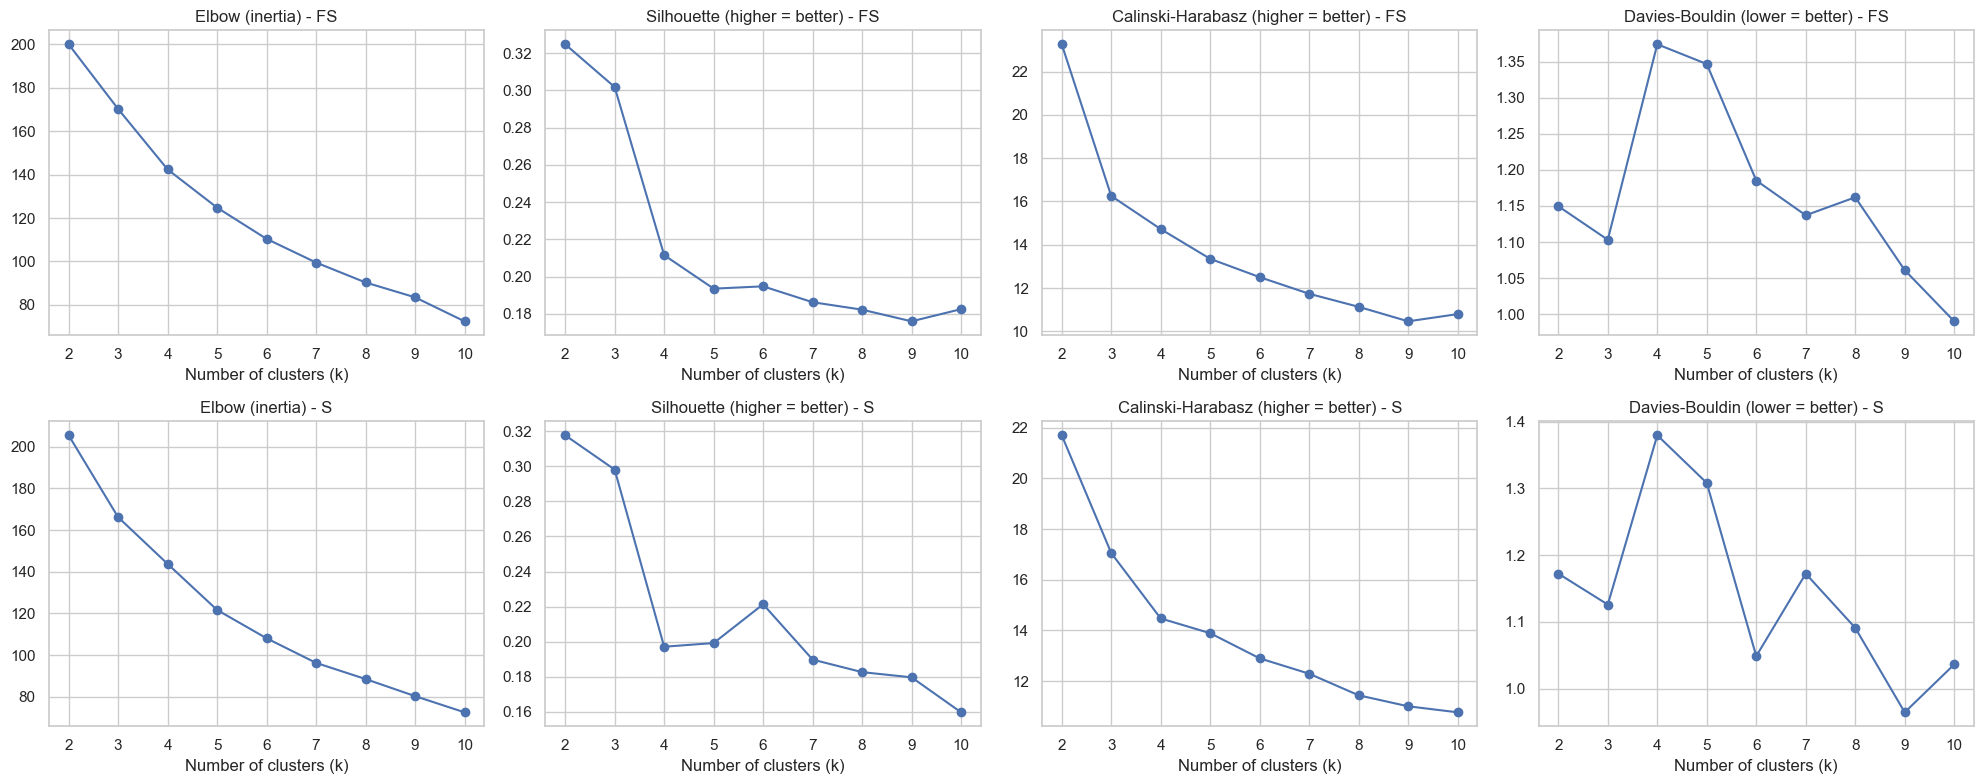

FS: a Dunn-only rule picks k=10, but its smallest cluster has 1 country and silhouette is only 0.183. Dunn is dominated by single-country clusters -> rejected as a sole rule.
S: a Dunn-only rule picks k=8, but its smallest cluster has 1 country and silhouette is only 0.183. Dunn is dominated by single-country clusters -> rejected as a sole rule.


In [4]:
#using dunn index and interia to determine elbow
def dunn_index(X, labels):
    d = pairwise_distances(X); cl = np.unique(labels)
    diam = max(d[np.ix_(labels == c, labels == c)].max() for c in cl if (labels == c).sum() > 1)
    sep  = min(d[np.ix_(labels == a, labels == b)].min() for i, a in enumerate(cl) for b in cl[i + 1:])
    return sep / diam

def fit_kmeans(X, k, seed=42, sample_weight=None):
    return KMeans(n_clusters=k, init="k-means++", n_init=50, max_iter=300,
                  random_state=seed).fit(X, sample_weight=sample_weight).labels_

def evaluate_k(X, ks=range(2, 11)):
    rows = []
    for k in ks:
        km = KMeans(n_clusters=k, init="k-means++", n_init=50, max_iter=300, random_state=42).fit(X)
        lab = km.labels_
        rows.append({"k": k, "Inertia": km.inertia_, "Dunn": dunn_index(X, lab),
                     "Silhouette": silhouette_score(X, lab),
                     "Calinski_Harabasz": calinski_harabasz_score(X, lab),
                     "Davies_Bouldin": davies_bouldin_score(X, lab),
                     "Min_cluster_size": int(np.bincount(lab).min())})
    return pd.DataFrame(rows).set_index("k")

k_tables = {name: evaluate_k(X) for name, X in SETS.items()}
for name, tab in k_tables.items():
    print(f"\n{name} scores"); display(tab.round(3))

# the four criteria that the decision below relies on (Dunn is tabulated above but not used as a rule)
panels = [("Inertia", "Elbow (inertia)"), ("Silhouette", "Silhouette (higher = better)"),
          ("Calinski_Harabasz", "Calinski-Harabasz (higher = better)"), ("Davies_Bouldin", "Davies-Bouldin (lower = better)")]
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for row, (name, tab) in enumerate(k_tables.items()):
    for col, (metric, title) in enumerate(panels):
        ax = axes[row, col]
        ax.plot(tab.index, tab[metric], marker="o")
        ax.set_title(f"{title} - {name}"); ax.set_xlabel("Number of clusters (k)"); ax.set_xticks(tab.index)
plt.tight_layout(); plt.savefig("visuals/kmeans_choose_k.png", dpi=300, bbox_inches="tight"); plt.show()

for name, tab in k_tables.items():
    kb = int(tab["Dunn"].idxmax())
    print(f"{name}: a Dunn-only rule picks k={kb}, but its smallest cluster has {tab.loc[kb,'Min_cluster_size']} country "
          f"and silhouette is only {tab.loc[kb,'Silhouette']:.3f}. Dunn is dominated by single-country clusters -> rejected as a sole rule.")

**Is there more cluster structure than chance?** A silhouette of 0.3 is conventionally "weak", and with 9 variables and 37 countries even structureless data produce a positive silhouette. The observed silhouette at k = 2 and k = 3 is therefore compared with its distribution when the same procedure (standardise, K-means with 50 starts) is applied to simulated single-cloud data with the same size and correlations.

In [5]:
def null_silhouette(X, k, reps=300, seed=7):
    cov = np.cov(X, rowvar=False)
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(reps):
        Y = StandardScaler().fit_transform(rng.multivariate_normal(np.zeros(X.shape[1]), cov, size=len(X)))
        out.append(silhouette_score(Y, KMeans(k, init="k-means++", n_init=50, random_state=42).fit_predict(Y)))
    return np.array(out)


rows = []
for name, X in SETS.items():
    for k in (2, 3):
        obs = k_tables[name].loc[k, "Silhouette"]
        nul = null_silhouette(X, k)
        rows.append({"Scores": name, "k": k, "Observed silhouette": obs, "No-structure mean": nul.mean(),
                     "No-structure 95th pct": np.percentile(nul, 95),
                     "p (no-structure >= observed)": (1 + (nul >= obs).sum()) / (len(nul) + 1)})
null_sil_table = pd.DataFrame(rows)
display(null_sil_table.round(3))

,Scores,k,Observed silhouette,No-structure mean,No-structure 95th pct,p (no-structure >= observed)
0,FS,2,0.325,0.285,0.345,0.133
1,FS,3,0.302,0.231,0.280,0.007
2,S,2,0.318,0.282,0.342,0.156
3,S,3,0.298,0.237,0.287,0.020


In [6]:
# Subsample stability: fit on random 80% of countries, compare with the full-data solution on the same countries
def subsample_stability(X, k, reps=100, frac=0.8, seed=0):
    rng = np.random.default_rng(seed); n = len(X); full = fit_kmeans(X, k)
    aris = []
    for r in range(reps):
        idx = rng.choice(n, int(frac * n), replace=False)
        lab = KMeans(k, n_init=20, random_state=r).fit_predict(X[idx])
        aris.append(adjusted_rand_score(full[idx], lab))
    return np.mean(aris), np.percentile(aris, 10)

rows = []
for name, X in SETS.items():
    for k in [2, 3, 4, 5]:
        m, p10 = subsample_stability(X, k)
        t = k_tables[name].loc[k]
        rows.append({"Scores": name, "k": k, "Silhouette": t.Silhouette, "CH": t.Calinski_Harabasz,
                     "DaviesBouldin(low=good)": t.Davies_Bouldin, "Dunn": t.Dunn,
                     "Min size": int(t.Min_cluster_size), "Subsample ARI mean": m, "Subsample ARI p10": p10})
k_compare = pd.DataFrame(rows).round(3)
display(k_compare)

,Scores,k,Silhouette,CH,DaviesBouldin(low=good),Dunn,Min size,Subsample ARI mean,Subsample ARI p10
0,FS,2,0.325,23.262,1.150,0.351,17,0.963,0.862
1,FS,3,0.302,16.253,1.103,0.344,3,0.768,0.513
2,FS,4,0.212,14.723,1.374,0.282,3,0.811,0.467
3,FS,5,0.194,13.348,1.347,0.282,3,0.695,0.507
4,S,2,0.318,21.702,1.172,0.270,17,0.994,1.000
5,S,3,0.298,17.054,1.126,0.367,4,0.915,0.699
6,S,4,0.197,14.472,1.380,0.250,4,0.629,0.476
7,S,5,0.199,13.889,1.308,0.250,3,0.703,0.535


**Decision: k = 3 (primary), with k = 2 reported as the coarse view.**

* **k = 2** has the highest silhouette and Calinski-Harabasz of all k tried, the highest subsample stability (S: 0.99, FS: 0.96), and FS and S agree on it perfectly (ARI = 1.0). It is the most reproducible split but the least informative (one group of 17 against one of 20). Its silhouette (0.32 to 0.33) is **not distinguishable** from what a single structureless cloud of the same size and correlations produces (p = 0.13 for FS, 0.16 for S), so by itself it is not evidence of two natural groups.
* **k = 3** has a better Davies-Bouldin score than k = 2 for both score sets (FS 1.10 against 1.15; S 1.13 against 1.17), a better Dunn index for S (0.37 against 0.27), and keeps every cluster at 3 or more countries (smallest: 3 for FS, 4 for S). Its silhouette (about 0.30) **does exceed** the no-structure range (p = 0.007 for FS, 0.020 for S; four tests were run and the p-values are not adjusted for that; only k = 2 and k = 3 were tested). Subsample stability is lower than for k = 2 but still high for S (0.92) and moderate for FS (0.77).
* **k = 4 and 5** fall clearly on silhouette (about 0.2) and Calinski-Harabasz; S subsample stability drops to 0.63-0.70 (FS stability is non-monotonic: 0.77 at k = 3 and 0.81 at k = 4), and k of 6 or more creates single-country clusters.

Summary for the report: k = 2 is the most reproducible answer and k = 3 is the finer grouping that has some support against chance, so k = 3 is retained. The evidence for cluster structure of any kind is nevertheless **weak**: the Hopkins statistic does not exceed its no-structure reference, the k = 3 silhouette is only about 0.30, and the k = 3 solution depends on a few countries. The groups should be presented as a *useful grouping of a continuum of countries*, not as sharply separated natural classes.

In [7]:
K = 3
df["FS_Cluster"] = fit_kmeans(X_FS_scaled, K)
df["S_Cluster"]  = fit_kmeans(X_S_scaled,  K)
for col in ["FS_Cluster", "S_Cluster"]:
    print(f"\n{col}")
    for c, countries in df.groupby(col)["Country"].apply(list).items():
        print(f"  Cluster {c} ({len(countries)}): {', '.join(countries)}")

# k = 2 coarse view (FS and S should coincide)
k2_FS, k2_S = fit_kmeans(X_FS_scaled, 2), fit_kmeans(X_S_scaled, 2)
print("\nk=2 ARI FS vs S:", round(adjusted_rand_score(k2_FS, k2_S), 3))

# Per-country silhouette: how well each country sits in its own cluster (negative = closer to another cluster)
df["S_Silhouette"] = silhouette_samples(X_S_scaled, df["S_Cluster"])
df["FS_Silhouette"] = silhouette_samples(X_FS_scaled, df["FS_Cluster"])
print("\nMean silhouette by cluster (S): ", df.groupby("S_Cluster")["S_Silhouette"].mean().round(3).to_dict())
print("Mean silhouette by cluster (FS):", df.groupby("FS_Cluster")["FS_Silhouette"].mean().round(3).to_dict())
print("Countries with a negative silhouette - S:", list(df.loc[df["S_Silhouette"] < 0, "Country"]),
      "| FS:", list(df.loc[df["FS_Silhouette"] < 0, "Country"]))
print("Five lowest per-country silhouettes (S):")
display(df.nsmallest(5, "S_Silhouette")[["Country", "S_Cluster", "S_Silhouette"]].round(3))


FS_Cluster
  Cluster 0 (3): Iran, Japan, South Korea
  Cluster 1 (21): Argentina, Brazil, Egypt, Finland, Germany, Greece, Hungary, India, Italy, Lithuania, Macedonia, Mexico, New Zealand, Peru, Poland, Portugal, Romania, Russia, South Africa, UK, USA
  Cluster 2 (13): Bangladesh, Canada, China, France, Ghana, Jordan, Malaysia, Nigeria, Pakistan, Taiwan, Thailand, Turkey, Vietnam

S_Cluster
  Cluster 0 (20): Argentina, Brazil, Egypt, Finland, Germany, Greece, Hungary, India, Italy, Lithuania, Macedonia, Mexico, New Zealand, Peru, Poland, Portugal, Romania, South Africa, UK, USA
  Cluster 1 (4): Bangladesh, Malaysia, Nigeria, Pakistan
  Cluster 2 (13): Canada, China, France, Ghana, Iran, Japan, Jordan, Russia, South Korea, Taiwan, Thailand, Turkey, Vietnam

k=2 ARI FS vs S: 1.0

Mean silhouette by cluster (S):  {0: 0.318, 1: 0.307, 2: 0.265}
Mean silhouette by cluster (FS): {0: 0.231, 1: 0.297, 2: 0.326}
Countries with a negative silhouette - S: [] | FS: ['Russia']
Five lowest per-coun

,Country,S_Cluster,S_Silhouette
19,Malaysia,1,0.078
28,Russia,2,0.136
5,Egypt,0,0.139
25,Poland,0,0.146
16,Jordan,2,0.169


## 3. Hierarchical clustering and linkage choice

In [8]:
methods = ["single", "complete", "average", "centroid", "ward"]
links = {(name, m): linkage(X, method=m, metric="euclidean") for name, X in SETS.items() for m in methods}

coph = pd.DataFrame({name: {m: cophenet(links[(name, m)], pdist(X))[0] for m in methods}
                     for name, X in SETS.items()}).round(3)
print("Cophenetic correlation"); display(coph)

rows = []
for (name, m), Z in links.items():
    lab = fcluster(Z, K, criterion="maxclust")
    rows.append({"Scores": name, "Linkage": m, "Cluster sizes at k=3": sorted(np.bincount(lab)[1:], reverse=True)})
display(pd.DataFrame(rows))
print("\nHighest cophenetic correlation:", {name: f"{coph[name].idxmax()} ({coph[name].max():.3f})" for name in SETS})

Cophenetic correlation


,FS,S
single,0.710,0.757
complete,0.606,0.585
average,0.741,0.800
centroid,0.748,0.786
ward,0.588,0.557


,Scores,Linkage,Cluster sizes at k=3
0,FS,single,"[35, 1, 1]"
1,FS,complete,"[20, 14, 3]"
2,FS,average,"[33, 3, 1]"
3,FS,centroid,"[35, 1, 1]"
4,FS,ward,"[20, 14, 3]"
5,S,single,"[35, 1, 1]"
6,S,complete,"[20, 14, 3]"
7,S,average,"[35, 1, 1]"
8,S,centroid,"[35, 1, 1]"
9,S,ward,"[20, 13, 4]"



Highest cophenetic correlation: {'FS': 'centroid (0.748)', 'S': 'average (0.800)'}


**Why Ward.** Cophenetic correlation is highest for average linkage on S (0.800) and centroid linkage on FS (0.748), but single and centroid linkage (both score sets) and average linkage on S give "chained" three-cluster partitions of sizes [35, 1, 1], and average linkage on FS gives [33, 3, 1]; none of these is a useful grouping. Complete linkage and Ward both give balanced partitions (FS: [20, 14, 3] for both; S: [20, 14, 3] and [20, 13, 4]). Cophenetic correlation is also not a like-for-like yardstick for Ward, whose merge heights measure increases in within-cluster variance rather than distances. Ward is retained because it targets the same within-cluster variance criterion as K-means (the S solutions are identical, ARI = 1.0).

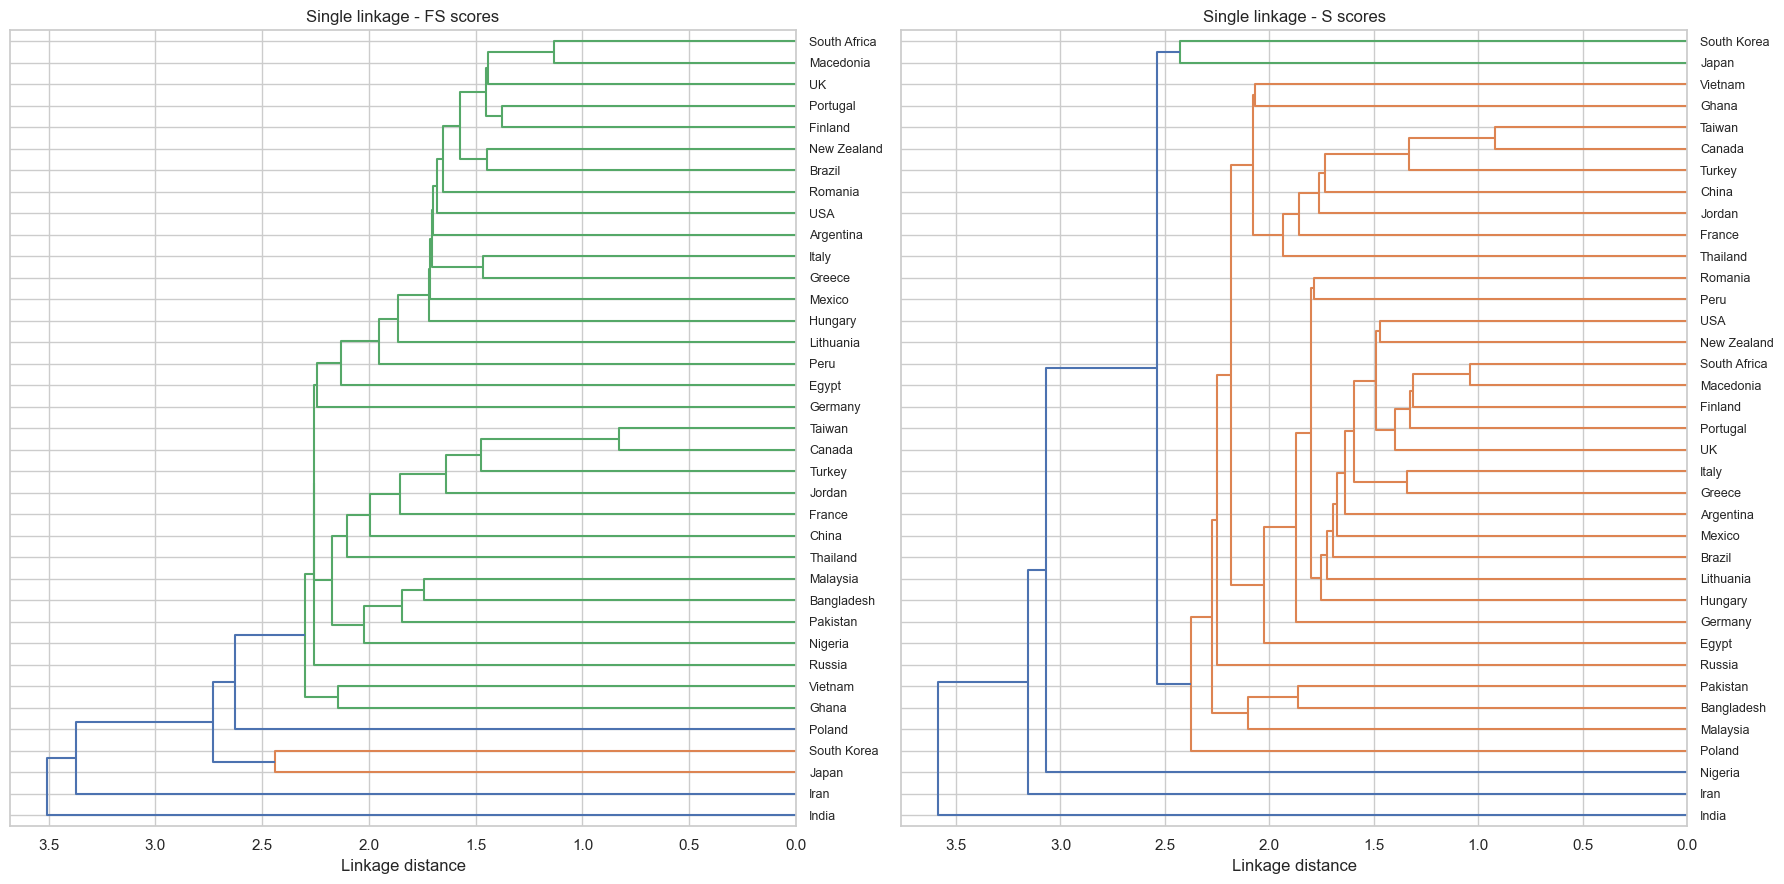

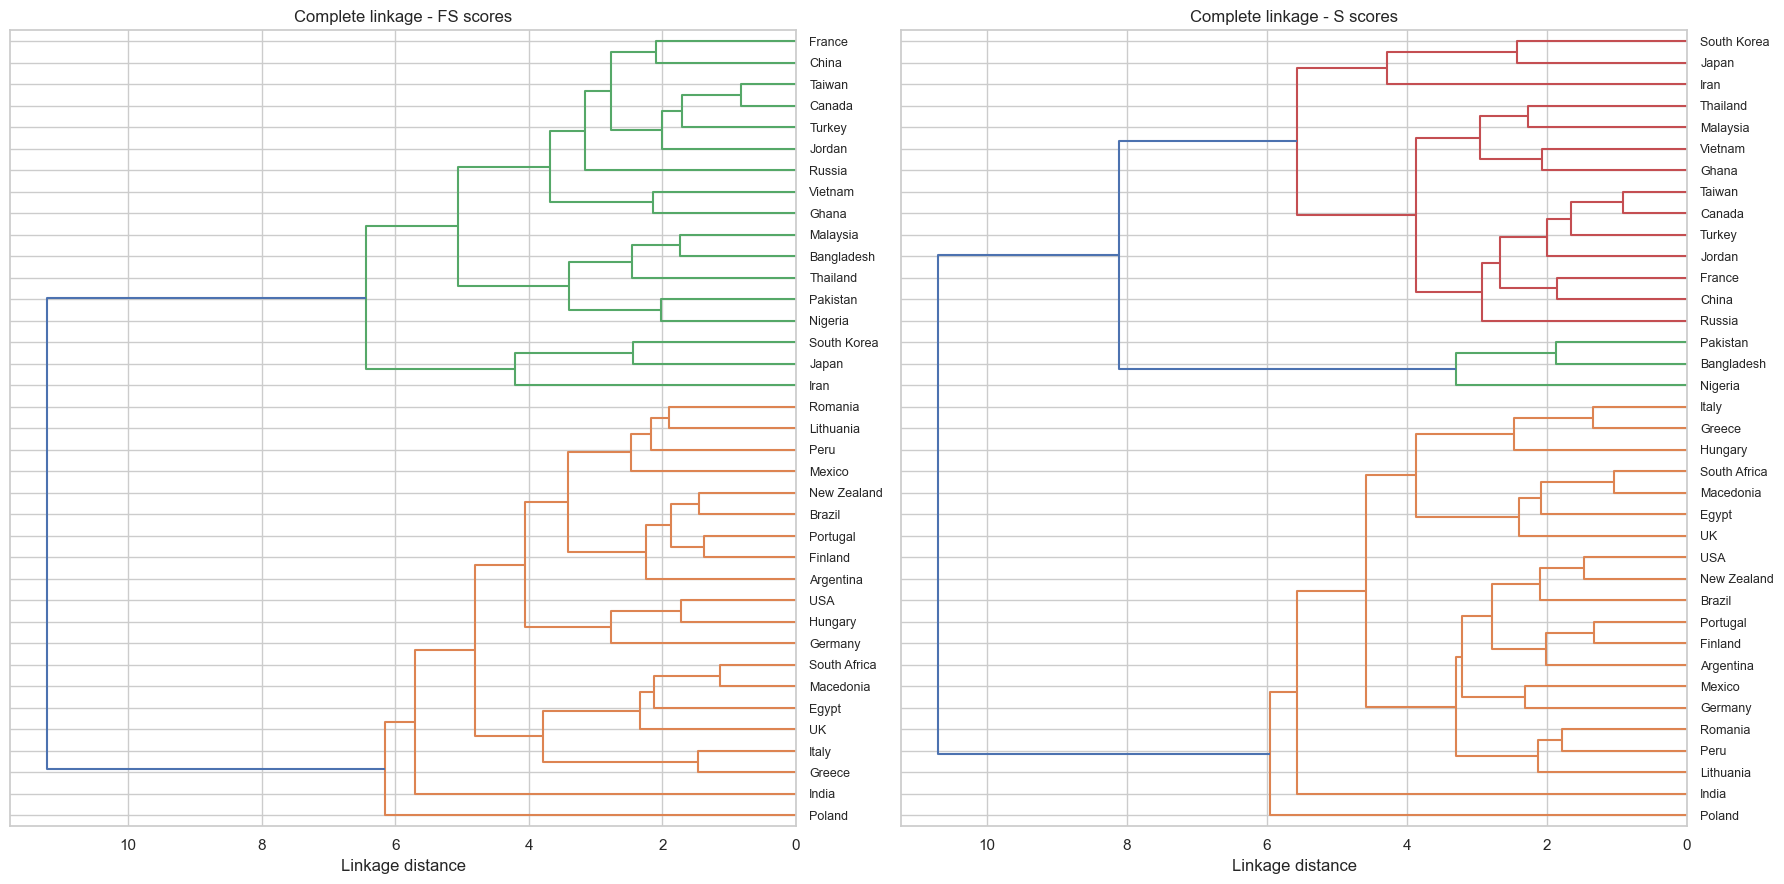

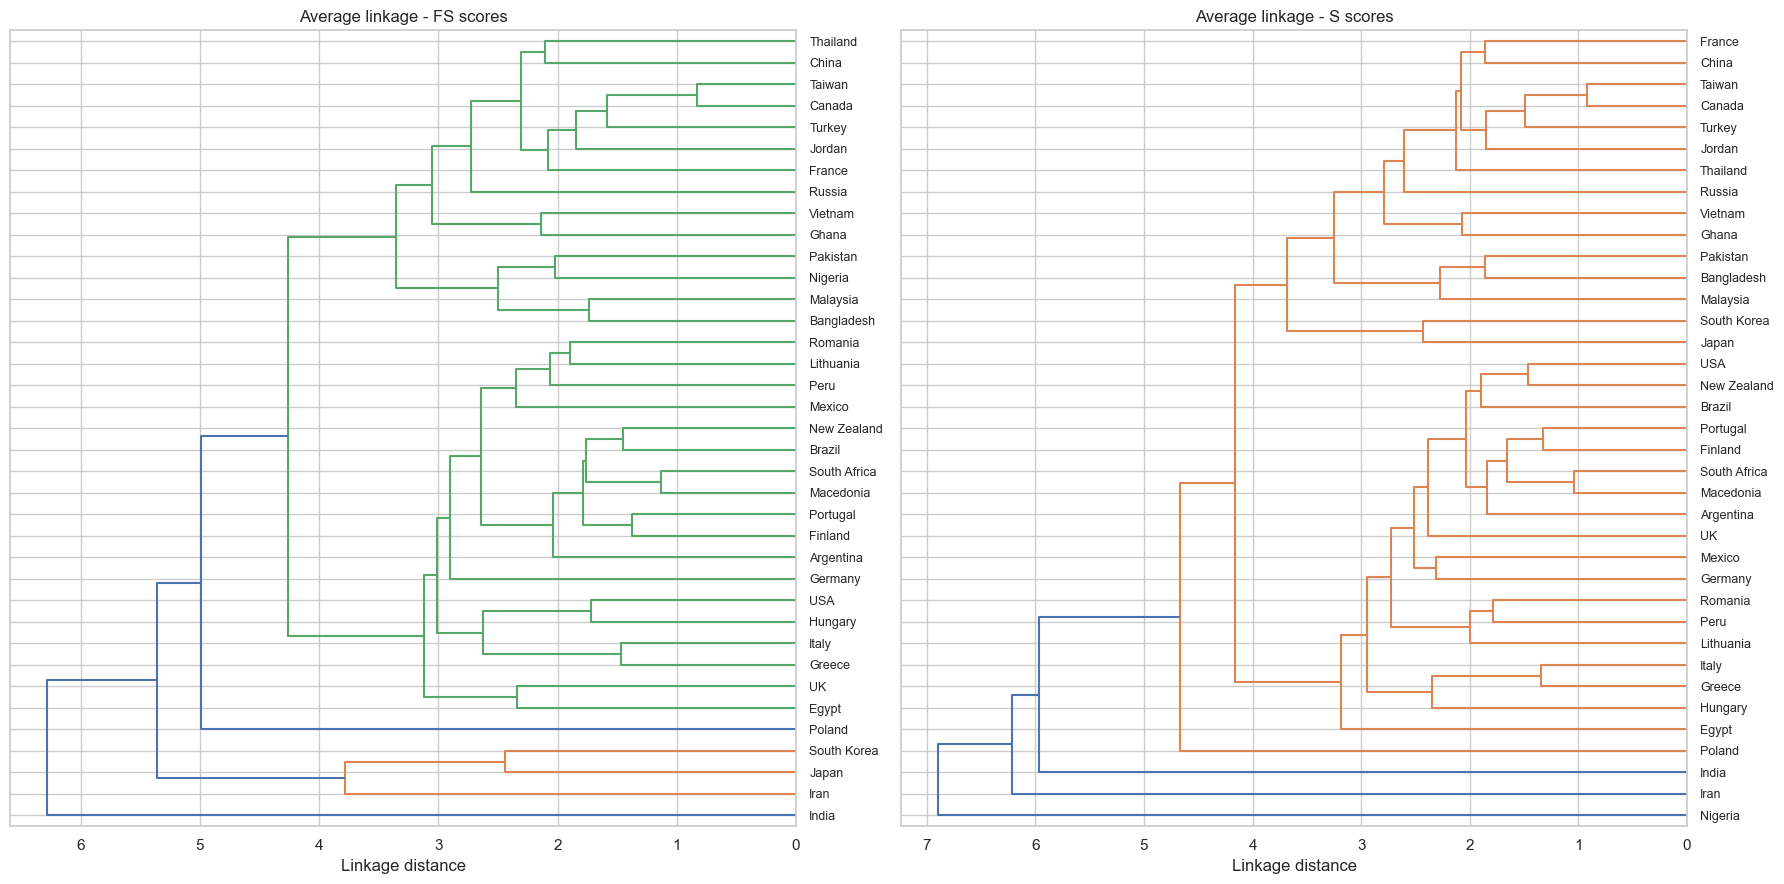

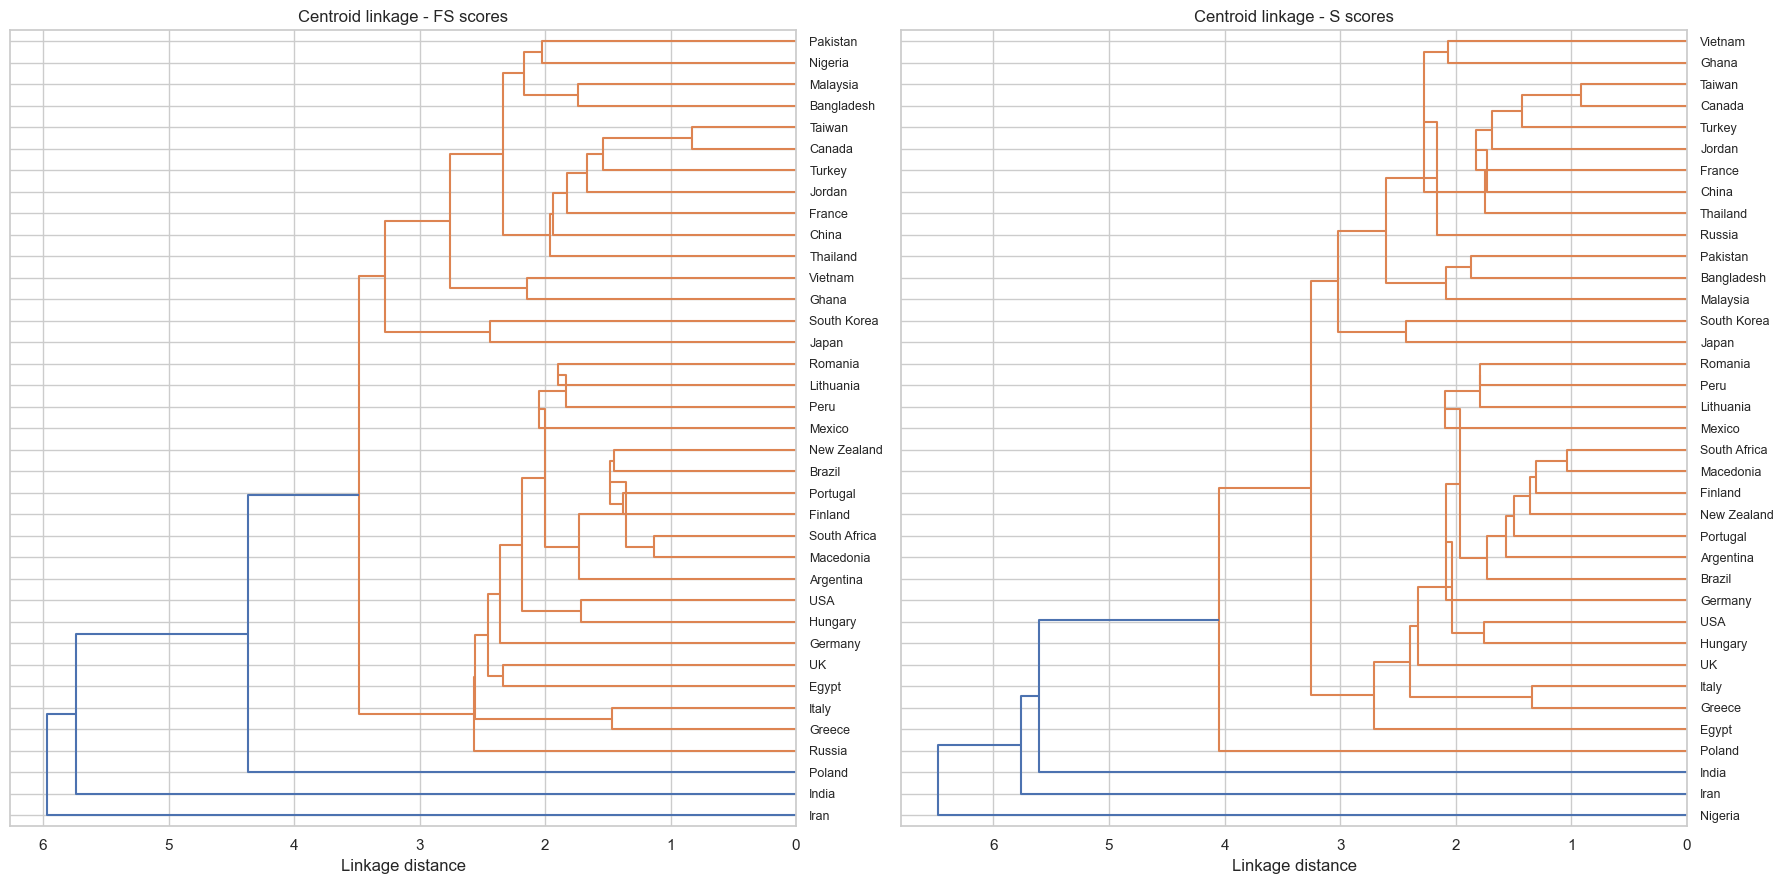

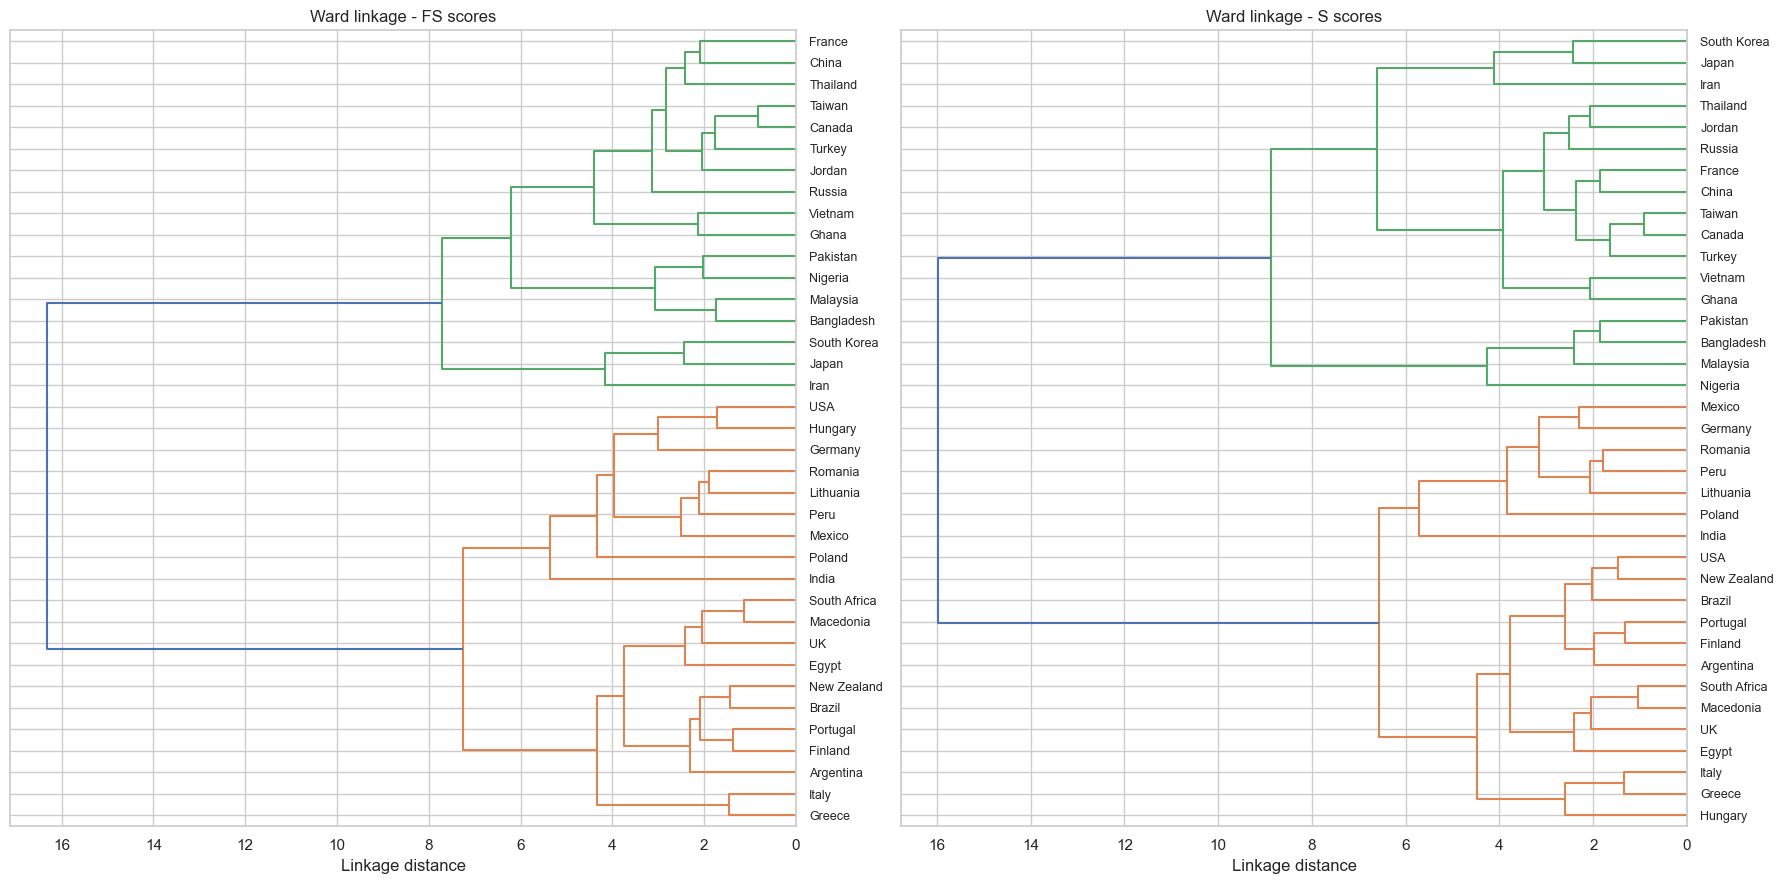

In [9]:
for m in methods:
    fig, axes = plt.subplots(1, 2, figsize=(18, 9))
    for ax, name in zip(axes, SETS):
        dendrogram(links[(name, m)], labels=df["Country"].values, orientation="left",
                   leaf_font_size=9, ax=ax)
        ax.set_title(f"{m.capitalize()} linkage - {name} scores"); ax.set_xlabel("Linkage distance")
    plt.tight_layout()
    plt.savefig(f"visuals/dendrogram_{m}.png", dpi=300, bbox_inches="tight")
    plt.show()

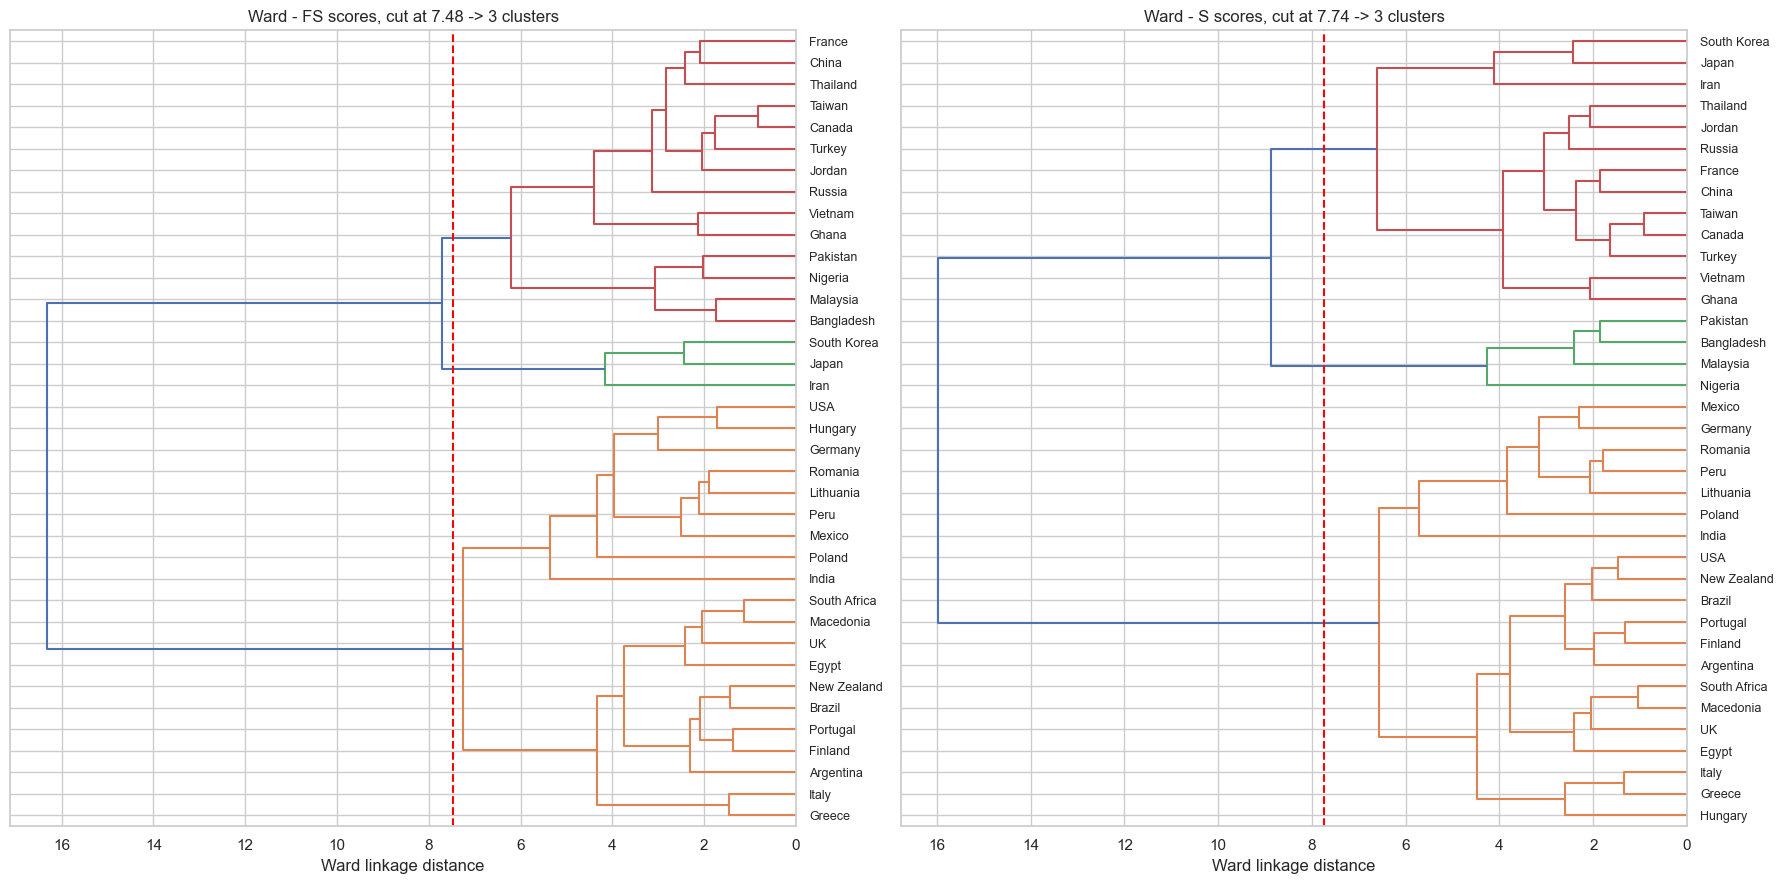

ARI sklearn Ward vs scipy Ward (S): 1.0


,Scores,ARI Euclidean vs Manhattan (complete)
0,FS,0.676
1,S,0.951


In [10]:
def height_for_k(Z, k):
    return (Z[-k, 2] + Z[-(k - 1), 2]) / 2   # any cut between these two merge heights gives exactly k clusters

fig, axes = plt.subplots(1, 2, figsize=(18, 9))
for ax, name in zip(axes, SETS):
    Z = links[(name, "ward")]; h = height_for_k(Z, K)
    dendrogram(Z, labels=df["Country"].values, orientation="left", leaf_font_size=9, color_threshold=h, ax=ax)
    ax.axvline(h, color="red", linestyle="--"); ax.set_title(f"Ward - {name} scores, cut at {h:.2f} -> {K} clusters")
    ax.set_xlabel("Ward linkage distance")
plt.tight_layout(); plt.savefig("visuals/dendrogram_ward_cut.png", dpi=300, bbox_inches="tight"); plt.show()

df["FS_Ward"] = fcluster(links[("FS", "ward")], K, criterion="maxclust") - 1
df["S_Ward"]  = fcluster(links[("S",  "ward")], K, criterion="maxclust") - 1
agg = AgglomerativeClustering(n_clusters=K, metric="euclidean", linkage="ward").fit_predict(X_S_scaled)
print("ARI sklearn Ward vs scipy Ward (S):", adjusted_rand_score(agg, df["S_Ward"]))

rows = []
for name, X in SETS.items():
    lab_e = fcluster(linkage(X, "complete", metric="euclidean"), K, "maxclust")
    lab_m = fcluster(linkage(X, "complete", metric="cityblock"), K, "maxclust")
    rows.append({"Scores": name, "ARI Euclidean vs Manhattan (complete)": round(adjusted_rand_score(lab_e, lab_m), 3)})
display(pd.DataFrame(rows))

## 4. Agreement between methods and score sets

In [11]:
rows = []
for k in range(2, 7):
    rows.append({"k": k,
                 "KMeans: FS vs S": adjusted_rand_score(fit_kmeans(X_FS_scaled, k), fit_kmeans(X_S_scaled, k)),
                 "Ward: FS vs S": adjusted_rand_score(fcluster(links[("FS","ward")], k, "maxclust"),
                                                      fcluster(links[("S","ward")], k, "maxclust"))})
print("FS vs S agreement (ARI) at matched k"); display(pd.DataFrame(rows).set_index("k").round(3))

pairs = {"FS: KMeans vs Ward": ("FS_Cluster", "FS_Ward"), "S: KMeans vs Ward": ("S_Cluster", "S_Ward"),
         "KMeans: FS vs S": ("FS_Cluster", "S_Cluster"), "Ward: FS vs S": ("FS_Ward", "S_Ward")}
print("Agreement between final solutions (k=3)")
display(pd.Series({n: adjusted_rand_score(df[a], df[b]) for n, (a, b) in pairs.items()}).round(3).to_frame("ARI"))
print("FS vs S K-means cross-tab"); display(pd.crosstab(df["FS_Cluster"], df["S_Cluster"], margins=True))

FS vs S agreement (ARI) at matched k


,KMeans: FS vs S,Ward: FS vs S
k,,
2,1.000,1.000
3,0.708,0.784
4,0.598,0.526
5,0.861,0.844
6,0.742,0.848


Agreement between final solutions (k=3)


,ARI
FS: KMeans vs Ward,0.899
S: KMeans vs Ward,1.000
KMeans: FS vs S,0.708
Ward: FS vs S,0.784


FS vs S K-means cross-tab


S_Cluster,0,1,2,All
FS_Cluster,,,,
0,0,0,3,3
1,20,0,1,21
2,0,4,9,13
All,20,4,13,37


## 5. Declared final solution

**Primary solution = S-score K-means, k = 3** (identical to S-score Ward, ARI = 1). The FS solutions and the ipsatised solution (each country's profile centred on its own mean, which removes the overall level of the profile) are treated as *robustness checks*.

Each country gets a **stability score**: the mean Jaccard overlap between its cluster-mates in the primary solution and in each of three alternative solutions (FS K-means, FS Ward, S ipsatised); no label matching is needed. The S Ward solution is identical to the primary one, so it is displayed but not averaged (it would only add a constant 1.0). **Core** means stability ≥ 0.75, otherwise **Borderline**. The 0.75 cut-off is a convention, so the number of Borderline countries at other cut-offs is also printed.

In [12]:
# Response-level (ipsatised) alternative: centre each country's standardised profile on its own mean
Zs = pd.DataFrame(X_S_scaled, columns=attributes)
X_ips = Zs.sub(Zs.mean(axis=1), axis=0).values
df["S_Ipsatised"] = fit_kmeans(X_ips, K)

primary = df["S_Cluster"].values
alternatives = {"FS_KMeans": df["FS_Cluster"].values, "FS_Ward": df["FS_Ward"].values,
                "S_Ward": df["S_Ward"].values, "S_Ipsatised": df["S_Ipsatised"].values}
STABILITY_ALTERNATIVES = ["FS_KMeans", "FS_Ward", "S_Ipsatised"]   # S_Ward duplicates the primary solution (checked below)
CORE_THRESHOLD = 0.75

def jaccard_stability(primary, alt):
    out = []
    for i in range(len(primary)):
        a = set(np.where(primary == primary[i])[0]); b = set(np.where(alt == alt[i])[0])
        out.append(len(a & b) / len(a | b))
    return np.array(out)

stab = pd.DataFrame({k: jaccard_stability(primary, v) for k, v in alternatives.items()}, index=df["Country"])
print("S_Ward identical to the primary solution for every country:", bool((stab["S_Ward"] == 1).all()))
stab["Stability"] = stab[STABILITY_ALTERNATIVES].mean(axis=1)
stab["Status"] = np.where(stab["Stability"] >= CORE_THRESHOLD, "Core", "Borderline")

print("Borderline countries (cluster-mates change under alternative methods):")
display(stab[stab["Status"] == "Borderline"].sort_values("Stability").round(2))
print(stab["Status"].value_counts().to_string())
print("\nNumber of Borderline countries at other cut-offs:",
      {t: int((stab["Stability"] < t).sum()) for t in (0.5, 0.6, 0.75, 0.9)})
print("\nPrimary (S K-means) clusters versus ipsatised clusters:")
display(pd.crosstab(df["S_Cluster"], df["S_Ipsatised"], margins=True))

S_Ward identical to the primary solution for every country: True
Borderline countries (cluster-mates change under alternative methods):


,FS_KMeans,FS_Ward,S_Ward,S_Ipsatised,Stability,Status
Country,,,,,,
South Korea,0.23,0.23,1.0,0.23,0.23,Borderline
Japan,0.23,0.23,1.0,0.23,0.23,Borderline
Iran,0.23,0.23,1.0,0.23,0.23,Borderline
Bangladesh,0.31,0.29,1.0,0.29,0.29,Borderline
Pakistan,0.31,0.29,1.0,0.29,0.29,Borderline
Nigeria,0.31,0.29,1.0,0.29,0.29,Borderline
Malaysia,0.31,0.29,1.0,0.29,0.29,Borderline
Russia,0.03,0.59,1.0,0.59,0.40,Borderline
Jordan,0.53,0.59,1.0,0.59,0.57,Borderline


Status
Core          20
Borderline    17

Number of Borderline countries at other cut-offs: {0.5: 8, 0.6: 17, 0.75: 17, 0.9: 17}

Primary (S K-means) clusters versus ipsatised clusters:


S_Ipsatised,0,1,2,All
S_Cluster,,,,
0,0,20,0,20
1,4,0,0,4
2,10,0,3,13
All,14,20,3,37


**What the stability scores show.** Only the group of 20 countries (S cluster 0, listed above) is *Core*: all 20 have stability 0.98, because they stay together under K-means, Ward, FS and the ipsatised solution. All 17 other countries are *Borderline* with stability of 0.57 or lower. There are no countries in between, so the Core/Borderline split is the same for any cut-off from 0.6 to 0.9 (the Borderline count falls to 8 only if the cut-off is lowered to 0.5), and the choice of 0.75 does not drive the result.

How the other 17 countries are divided depends on the scoring and on the overall level of each country's profile:

* Under **S** scores they divide into a 4-country group (Bangladesh, Malaysia, Nigeria, Pakistan) and a 13-country group (K-means = Ward).
* Under **FS** scores, Iran, Japan and South Korea form their own group of 3; Bangladesh, Malaysia, Nigeria and Pakistan are merged with 9 of the 13 (Canada, China, France, Ghana, Jordan, Taiwan, Thailand, Turkey, Vietnam); and Russia joins the group of 20.
* After the **ipsatised** correction (each country's profile centred on its own mean), the 4-country group is *not* separate: it merges with 10 of the 13 (all except Iran, Japan and South Korea, which form their own group of 3). Part of the 4-country group's distinctness is therefore its overall low level on most scores rather than a different *shape* of profile. Whether that low level is real or reflects how respondents in those countries use the rating scales cannot be decided from these data.

Report this as: one robust finding (a group of 20 countries that are, relative to the average country, high on work satisfaction, work overload, work-home conflict, exhaustion and exit intentions, and low on job insecurity and self-efficacy) and finer subdivisions of the remaining 17 that depend on the scoring and on profile level.

In [13]:
# Name the clusters from their standardised S-score profile
# Names describe the profile relative to the 37-country average.
prof = pd.DataFrame(X_S_scaled, columns=attributes).groupby(df["S_Cluster"]).mean()
LOAD_EXIT = ["WS", "WO", "WH", "WE", "TI", "TA"]
c_low  = prof["WS"].idxmin()                                  # lowest work satisfaction
c_net  = prof.drop(index=c_low)["JI"].idxmax()                # highest job insecurity among the remaining two
c_high = [c for c in prof.index if c not in (c_low, c_net)][0]

# each name must agree with the sign pattern it claims (fails loudly if the data or the clustering change)
assert (prof.loc[c_high, LOAD_EXIT] > 0).all() and prof.loc[c_high, "JI"] < 0
assert (prof.loc[c_low, LOAD_EXIT] < 0).all()
assert (prof.loc[c_net, ["FC", "JI", "SE"]] > 0).all() and prof.loc[c_net, "TA"] < 0

names = {c_high: "High load, high satisfaction, high exit intent",
         c_low:  "Low load, low satisfaction, low exit intent",
         c_net:  "High insecurity & self-efficacy, low exit intent"}
df["Cluster_Name"] = df["S_Cluster"].map(names)

for c, nm in names.items():
    print(f"\nCluster {c} - {nm} ({(df['S_Cluster']==c).sum()} countries):")
    print("  " + ", ".join(df.loc[df["S_Cluster"] == c, "Country"]))

fs_cluster_profiles = pd.DataFrame(X_FS_scaled, columns=attributes).groupby(df["FS_Cluster"]).mean()
s_cluster_profiles  = prof
s_raw_profiles = df.groupby("S_Cluster")[S_columns].mean().rename(columns=dict(zip(S_columns, attributes)))
print("\nFS cluster profiles (standardised):"); display(fs_cluster_profiles.round(2))
print("S cluster profiles (standardised):");  display(s_cluster_profiles.round(2))
print("S cluster means (original units):");    display(s_raw_profiles.round(2))


Cluster 0 - High load, high satisfaction, high exit intent (20 countries):
  Argentina, Brazil, Egypt, Finland, Germany, Greece, Hungary, India, Italy, Lithuania, Macedonia, Mexico, New Zealand, Peru, Poland, Portugal, Romania, South Africa, UK, USA

Cluster 1 - Low load, low satisfaction, low exit intent (4 countries):
  Bangladesh, Malaysia, Nigeria, Pakistan

Cluster 2 - High insecurity & self-efficacy, low exit intent (13 countries):
  Canada, China, France, Ghana, Iran, Japan, Jordan, Russia, South Korea, Taiwan, Thailand, Turkey, Vietnam

FS cluster profiles (standardised):


,FC,JI,SE,WS,WO,WH,WE,TI,TA
FS_Cluster,,,,,,,,,
0,2.20,1.87,2.24,-1.03,-0.49,-0.46,-1.04,-0.16,-1.21
1,-0.14,-0.69,-0.46,0.73,0.50,0.59,0.56,0.40,0.66
2,-0.28,0.68,0.22,-0.94,-0.69,-0.85,-0.66,-0.60,-0.79


S cluster profiles (standardised):


,FC,JI,SE,WS,WO,WH,WE,TI,TA
S_Cluster,,,,,,,,,
0,-0.15,-0.68,-0.52,0.67,0.52,0.59,0.56,0.46,0.76
1,-1.23,0.36,-0.20,-1.76,-1.72,-1.89,-1.45,-1.15,-1.21
2,0.61,0.94,0.86,-0.49,-0.26,-0.33,-0.42,-0.36,-0.80


S cluster means (original units):


,FC,JI,SE,WS,WO,WH,WE,TI,TA
S_Cluster,,,,,,,,,
0,5.75,5.83,7.57,14.14,12.41,10.55,13.41,10.33,12.03
1,5.20,6.54,7.91,11.56,10.22,8.30,11.08,9.06,9.97
2,6.13,6.93,9.03,12.91,11.64,9.71,12.27,9.69,10.40


*Reading the names.* "Load" refers to work overload, work-home conflict and work exhaustion (WO, WH, WE); "exit intent" refers to turnover and turnaway intention (TI, TA). The names are descriptive labels of the standardised profile, not causal claims. The six variables WS, WO, WH, WE, TI and TA move together across countries (Section 6), so the clusters differ mainly in the overall level of these six; FC, JI and SE are what set the third cluster apart from the other two.

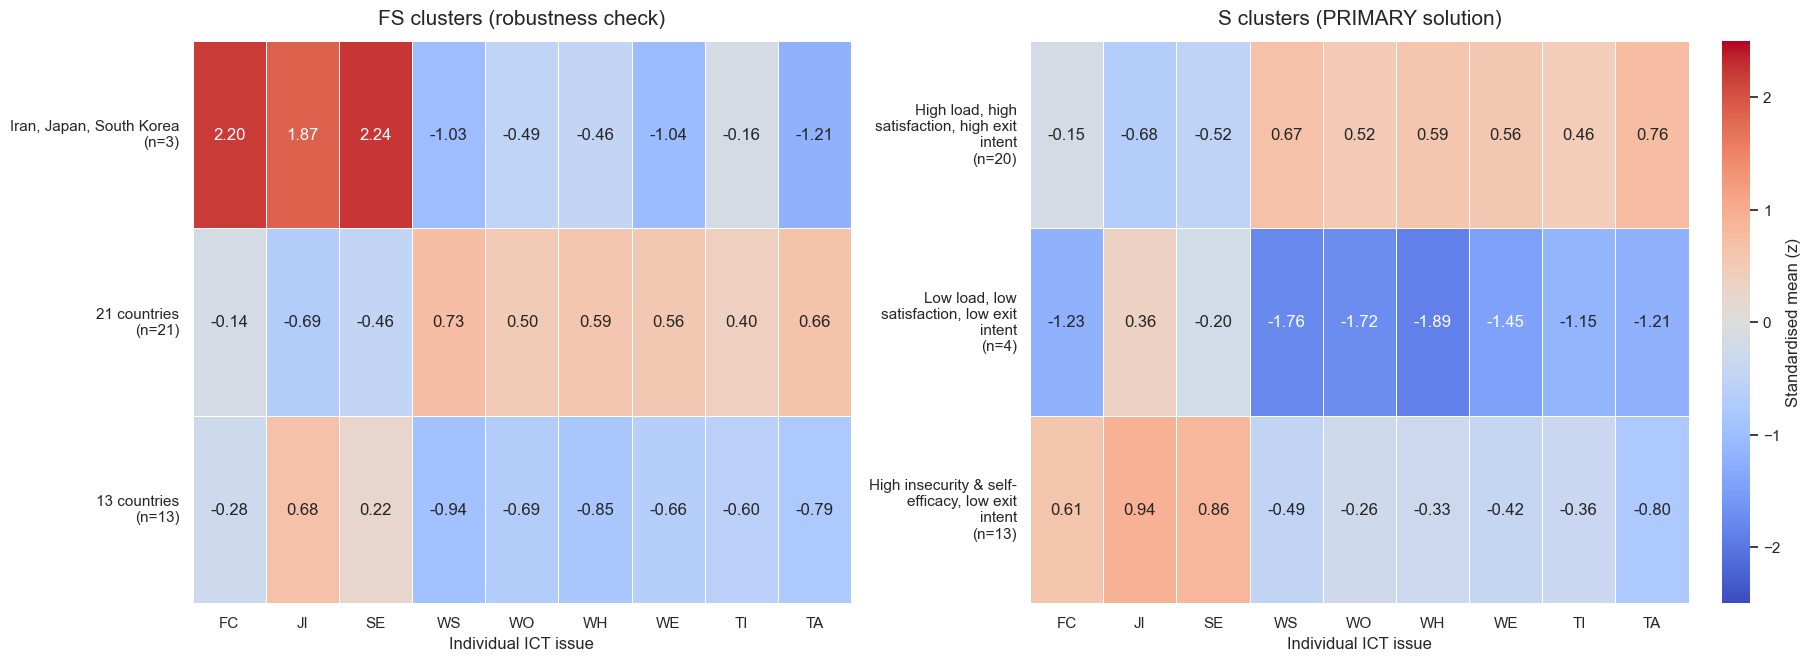

In [14]:
# Cluster-profile heatmaps
def wrap_label(text, width):
    return "\n".join(textwrap.wrap(text, width))

s_labels = {c: wrap_label(names[c], 24) + f"\n(n={(df['S_Cluster'] == c).sum()})" for c in names}
fs_labels = {}
for c in fs_cluster_profiles.index:
    members = df.loc[df["FS_Cluster"] == c, "Country"].tolist()
    fs_labels[c] = (wrap_label(", ".join(members), 38) if len(members) <= 4 else f"{len(members)} countries") + f"\n(n={len(members)})"

fig, axes = plt.subplots(1, 2, figsize=(18, 6.5), constrained_layout=True)
heat_kw = dict(annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-2.5, vmax=2.5, linewidths=0.5)
sns.heatmap(fs_cluster_profiles.rename(index=fs_labels), ax=axes[0], cbar=False, **heat_kw)
axes[0].set_title("FS clusters (robustness check)", fontsize=15, pad=12)
sns.heatmap(s_cluster_profiles.rename(index=s_labels), ax=axes[1], cbar_kws={"label": "Standardised mean (z)"}, **heat_kw)
axes[1].set_title("S clusters (PRIMARY solution)", fontsize=15, pad=12)
for ax in axes:
    ax.set_xlabel("Individual ICT issue"); ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=0); ax.tick_params(axis="y", rotation=0)
plt.savefig("visuals/cluster_profiles_heatmap.png", dpi=300, bbox_inches="tight"); plt.show()

## 6. Describing the clusters (descriptive only)

Eta² shows how much of each variable's spread lies *between* clusters. **Do not quote p-values from ANOVA/Kruskal here**: the clusters were built from these very variables, so the tests are circular and always "significant". Real validation is Section 7.

In [15]:
rows = []
for a, col in zip(attributes, S_columns):
    g = [x[col].values for _, x in df.groupby("S_Cluster")]
    gm = df[col].mean()
    rows.append({"Attribute": a,
                 "eta_sq (share of variance between clusters)": sum(len(x) * (x.mean() - gm) ** 2 for x in g) / ((df[col] - gm) ** 2).sum()})
display(pd.DataFrame(rows).round(3))

# Correlation structure that drives the clustering (S scores)
corr_S = pd.DataFrame(X_S_scaled, columns=attributes).corr()
block = corr_S.loc[LOAD_EXIT, LOAD_EXIT].values[np.triu_indices(6, 1)]
print("Mean correlation among WS, WO, WH, WE, TI, TA (S scores):", round(float(block.mean()), 2))
print("Variance explained by the first two principal components (S):",
      np.round(PCA().fit(X_S_scaled).explained_variance_ratio_[:2], 3))

,Attribute,eta_sq (share of variance between clusters)
0,FC,0.305
1,JI,0.573
2,SE,0.408
3,WS,0.662
4,WO,0.488
5,WH,0.611
6,WE,0.461
7,TI,0.304
8,TA,0.695


Mean correlation among WS, WO, WH, WE, TI, TA (S scores): 0.58
Variance explained by the first two principal components (S): [0.516 0.221]


## 7. Robustness checks

In [16]:
#Seed stability: one random start vs the best of 50
base = fit_kmeans(X_S_scaled, K, seed=0)
single = [round(adjusted_rand_score(base, KMeans(K, init="random", n_init=1, random_state=s).fit_predict(X_S_scaled)), 2) for s in range(10)]
print("(a) ARI of single random-start runs vs best solution:", single, "-> hence n_init = 50")

#Leave-out sensitivity, for both score sets. The country lists come from the preprocessing notebook's output files.
flagged = list(dict.fromkeys(pd.read_csv("outlier_investigation.csv")["Country"]))           # IQR-flagged countries
mv = pd.read_csv("mahalanobis_outlier_check.csv")                                            # chi-square-flagged countries
mv_flagged = sorted(mv.loc[mv["Flagged_Multivariate"], "Country"].unique())                  
drop_sets = [([c], c) for c in flagged]
drop_sets += [(flagged, f"ALL {len(flagged)} IQR-flagged"),
              (mv_flagged, "Multivariate-flagged: " + ", ".join(mv_flagged))]
rows = []
for name, cols, ref in [("FS", FS_columns, "FS_Cluster"), ("S", S_columns, "S_Cluster")]:
    for drop, label in drop_sets:
        mask = ~df["Country"].isin(drop)
        lab = fit_kmeans(StandardScaler().fit_transform(df.loc[mask, cols]), K)
        rows.append({"Scores": name, "Dropped": label,
                     "ARI vs full solution": round(adjusted_rand_score(df.loc[mask, ref], lab), 3)})
loo = pd.DataFrame(rows)
print("(b) Leave-out sensitivity"); display(loo.pivot(index="Dropped", columns="Scores", values="ARI vs full solution"))

# (c) Sample-size sensitivity: country means rest on very different Ns
small = df["Num"] < 110
print("\n(c) Countries with Num < 110:", ", ".join(df.loc[small, "Country"]))
lab_small = fit_kmeans(StandardScaler().fit_transform(df.loc[~small, S_columns]), K)
print("    ARI dropping them (S):", round(adjusted_rand_score(df.loc[~small, "S_Cluster"], lab_small), 3))
w = np.sqrt(df["Num"].values)
lab_w = fit_kmeans(X_S_scaled, K, sample_weight=w)
print("    ARI sqrt(Num)-weighted K-means vs primary (S):", round(adjusted_rand_score(df["S_Cluster"], lab_w), 3))

# (d) Profile-level (ipsatised) check
for k in [2, 3, 4]:
    lab = fit_kmeans(X_ips, k)
    print(f"(d) Ipsatised k={k}: silhouette={silhouette_score(X_ips, lab):.3f}, ARI vs primary k=3: {adjusted_rand_score(lab, df['S_Cluster']):.2f}")

(a) ARI of single random-start runs vs best solution: [1.0, 0.45, 0.52, 0.55, 0.57, 0.87, 0.68, 0.68, 0.53, 1.0] -> hence n_init = 50
(b) Leave-out sensitivity


Scores,FS,S
Dropped,,
ALL 8 IQR-flagged,0.512,0.529
India,1.000,1.000
Iran,0.562,1.000
Italy,0.896,1.000
Japan,0.562,1.000
"Multivariate-flagged: Iran, Nigeria, Poland",0.548,0.528
Nigeria,0.524,0.701
Pakistan,0.517,0.952
Poland,0.896,1.000



(c) Countries with Num < 110: Greece, Nigeria, UK
    ARI dropping them (S): 0.669
    ARI sqrt(Num)-weighted K-means vs primary (S): 1.0
(d) Ipsatised k=2: silhouette=0.338, ARI vs primary k=3: 0.84
(d) Ipsatised k=3: silhouette=0.277, ARI vs primary k=3: 0.78
(d) Ipsatised k=4: silhouette=0.192, ARI vs primary k=3: 0.45


**Reading the robustness results.** (a) Single random starts often land in poor local optima (ARI as low as 0.45), so `n_init = 50` is needed. (b) The S solution is unaffected by dropping any single IQR-flagged country except Nigeria (ARI 0.70) and, less so, Pakistan (0.95). **Dropping all eight IQR-flagged countries, or the three multivariate-flagged countries (Iran, Nigeria, Poland) together, gives an ARI of about 0.53 for S**: the three-group structure is not stable once the extreme countries are removed. The FS solution is more sensitive still (ARI about 0.51 to 0.56 whenever Iran, Japan, Nigeria or Pakistan, or either combined set, is dropped), because a few extreme countries define its small clusters. (c) Dropping the three countries with fewer than 110 respondents (Greece, Nigeria, UK) gives ARI 0.67 for S, so the small-group result leans on Nigeria's small sample; weighting by sqrt(Num) leaves the solution unchanged (ARI 1.0). (d) The ipsatised check at k = 3 gives ARI 0.78 against the primary solution, but see Section 5: that number is carried by the large group and hides the merge of the 4-country group into 10 of the 13.

**Note on the multivariate outlier test (preprocessing notebook).** With n = 37 and p = 9 the covariance matrix is poorly estimated, so Mahalanobis distances are approximate. Three country-score-set pairs exceed the χ² cutoff: Poland (FS), Iran (S) and Nigeria (S); about 3.7 flags would be expected by chance among the 74 tests. No country is removed, and Section 8(b) shows how the clustering responds when each flagged country, or the multivariate-flagged countries together, are left out.

## 8. Visual summary: countries in principal-component space

The plot projects the 9 standardised S variables onto the first two principal components. Filled markers are **Core** countries and open markers are **Borderline** countries (Section 5). Grey arrows show the variable loadings, drawn four times their true length so that they are visible.

Variance explained by PCs: [0.516 0.221 0.083 0.057 0.044 0.033 0.023 0.015 0.01 ]


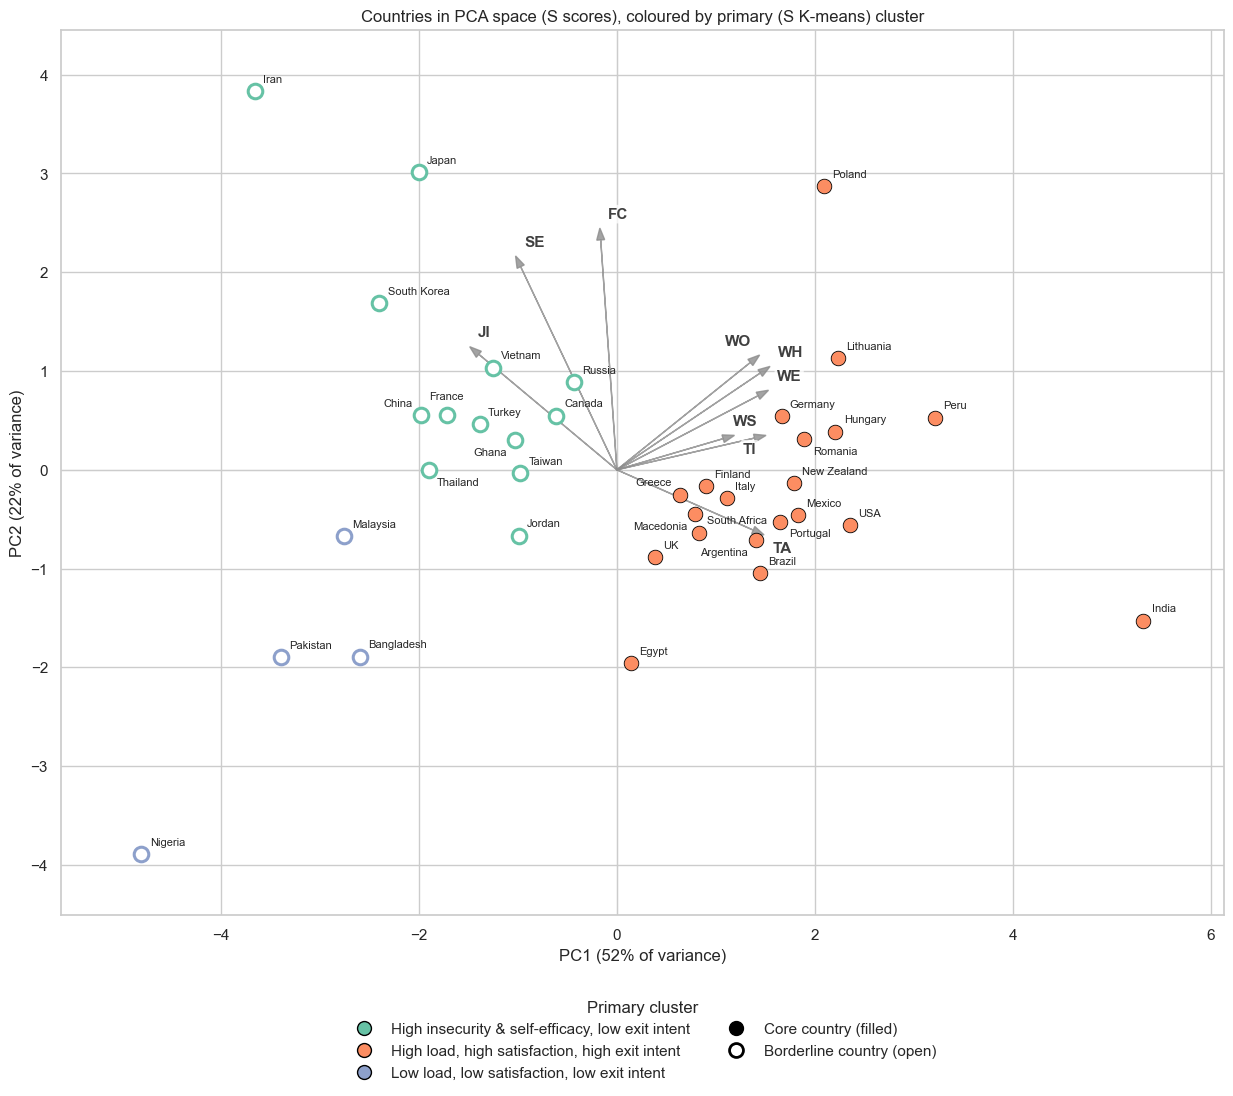

In [17]:
pca_full = PCA().fit(X_S_scaled)
pca = PCA(n_components=2).fit(X_S_scaled); pcs = pca.transform(X_S_scaled)
print("Variance explained by PCs:", np.round(pca_full.explained_variance_ratio_, 3))


def place_labels(ax, xs, ys, texts, extra_markers_xy=None, own_markers=True, placed=None, marker_pt2=110, **text_kw):
    """Greedy label placement. For each anchor point (most crowded first) try offsets in widening rings and keep the
    first that overlaps no other label or marker; if none is free, keep the least-overlapping one.
    Returns the list of label bounding boxes (so that further labels can avoid them)."""
    fig = ax.figure
    fig.canvas.draw()
    try:
        renderer = fig.canvas.get_renderer()
    except AttributeError:
        renderer = fig._get_renderer()
    half = 0.5 * np.sqrt(marker_pt2) * fig.dpi / 72 + 1                         
    anchors = ax.transData.transform(np.column_stack([xs, ys]))
    box_at = lambda x, y: Bbox.from_extents(x - half, y - half, x + half, y + half)
    own = [box_at(x, y) for x, y in anchors] if own_markers else [None] * len(anchors)
    extra = [] if extra_markers_xy is None else [box_at(x, y) for x, y in ax.transData.transform(extra_markers_xy)]
    placed = [] if placed is None else list(placed)

    ring0 = [(6, 5, "left", "bottom"), (6, -5, "left", "top"), (-6, 5, "right", "bottom"), (-6, -5, "right", "top"),
             (0, 10, "center", "bottom"), (0, -10, "center", "top"), (10, 0, "left", "center"), (-10, 0, "right", "center")]
    def ring(r):
        d = int(r * 0.7)
        return [(r, d, "left", "bottom"), (r, -d, "left", "top"), (-r, d, "right", "bottom"), (-r, -d, "right", "top"),
                (0, r, "center", "bottom"), (0, -r, "center", "top"), (r, 0, "left", "center"), (-r, 0, "right", "center")]
    offsets = ring0 + ring(20) + ring(32) + ring(46) + ring(62)

    crowd = [sum(np.hypot(*(anchors[i] - anchors[j])) < 70 for j in range(len(anchors)) if j != i) for i in range(len(anchors))]
    for i in sorted(range(len(texts)), key=lambda k: -crowd[k]):
        best = None
        for dx, dy, ha, va in offsets:
            ann = ax.annotate(texts[i], (xs[i], ys[i]), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va, zorder=5,
                              arrowprops=dict(arrowstyle="-", color="0.6", lw=0.5) if max(abs(dx), abs(dy)) > 12 else None,
                              **text_kw)
            box = ann.get_window_extent(renderer)
            n_over = (sum(box.overlaps(p) for p in placed) + sum(box.overlaps(m) for m in extra)
                      + sum(box.overlaps(m) for j, m in enumerate(own) if m is not None and j != i))
            if best is None or n_over < best[0]:
                if best is not None:
                    best[1].remove()
                best = (n_over, ann, box)
            else:
                ann.remove()
            if best[0] == 0:
                break
        placed.append(best[2])
    return placed


palette = dict(zip(sorted(df["Cluster_Name"].unique()), sns.color_palette("Set2", 3)))
core = (stab["Status"] == "Core").values

fig, ax = plt.subplots(figsize=(15, 11.5))
for nm, colr in palette.items():
    sel = (df["Cluster_Name"] == nm).values
    ax.scatter(pcs[sel & core, 0], pcs[sel & core, 1], s=110, color=colr, edgecolor="black", linewidth=0.6, zorder=3)
    ax.scatter(pcs[sel & ~core, 0], pcs[sel & ~core, 1], s=110, facecolor="white", edgecolor=colr, linewidth=2.2, zorder=3)

ARROW_SCALE = 4
tips = []
for j, a in enumerate(attributes):
    lx, ly = pca.components_[0, j] * ARROW_SCALE, pca.components_[1, j] * ARROW_SCALE
    ax.arrow(0, 0, lx, ly, color="0.55", alpha=0.8, head_width=0.08, length_includes_head=True, zorder=2)
    tips.append((lx, ly))
tips = np.array(tips)

ax.axhline(0, color="0.8", lw=0.8, zorder=1); ax.axvline(0, color="0.8", lw=0.8, zorder=1)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
ax.set_title("Countries in PCA space (S scores), coloured by primary (S K-means) cluster")
ax.margins(0.08)
ax.set_aspect("equal", adjustable="datalim")

handles = [Line2D([], [], marker="o", ls="", markersize=10, markerfacecolor=c, markeredgecolor="black", label=nm)
           for nm, c in palette.items()]
handles += [Line2D([], [], marker="o", ls="", markersize=10, markerfacecolor="black", markeredgecolor="black", label="Core country (filled)"),
            Line2D([], [], marker="o", ls="", markersize=10, markerfacecolor="white", markeredgecolor="black", markeredgewidth=2, label="Borderline country (open)")]
ax.legend(handles=handles, title="Primary cluster", loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)

arrow_boxes = place_labels(ax, tips[:, 0], tips[:, 1], attributes, extra_markers_xy=pcs, own_markers=False,
                           color="0.25", fontsize=11, fontweight="bold",
                           bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75))
place_labels(ax, pcs[:, 0], pcs[:, 1], df["Country"].tolist(), placed=arrow_boxes, fontsize=8)
plt.savefig("visuals/pca_biplot.png", dpi=300, bbox_inches="tight"); plt.show()

## 9. Summary and limitations

* **Final grouping.** S-score K-means with k = 3 gives groups of 20, 4 and 13 countries. FS and S give the same grouping at k = 2 (ARI = 1.0) and different groupings at k = 3 (ARI 0.71 for K-means, 0.78 for Ward): FS isolates Iran, Japan and South Korea, whereas S isolates Bangladesh, Malaysia, Nigeria and Pakistan. Nigeria is the country with the largest FS-versus-S discrepancy on every one of the nine attributes.
* **Strength of the evidence.** The Hopkins statistic does not exceed its no-structure reference; the k = 3 silhouette (about 0.30) is above the no-structure range but the k = 2 silhouette is not; 17 of 37 countries are Borderline; and the S solution changes markedly (ARI about 0.53) when the extreme countries are dropped. The grouping is a weak, descriptive partition of a continuum, and should be reported that way.
* **Small sample.** The 4-country group rests on Nigeria (the smallest sample, 93 respondents) and Pakistan; the result for S drops to ARI 0.67 when the three countries with fewer than 110 respondents are removed.